# Bài 6 · Mạng nơ-ron cho văn bản với PyTorch

**Thời lượng gợi ý:** 180 phút · **Cần:** Bài 3, Bài 5 · **Chạy được trên CPU**

## Mục tiêu

1. Hiểu hồi quy softmax là "mạng nơ-ron một lớp"; **tự tính gradient** và kiểm tra bằng sai phân số.
2. Dựng pipeline văn bản trong PyTorch: từ điển, mã hóa, đệm (padding), `Dataset`, `DataLoader`.
3. Xây hai mô hình: **trung bình embedding** (kiểu fastText) và **CNN 1 chiều** (bắt cụm từ).
4. Viết vòng huấn luyện đầy đủ: tối ưu, đánh giá, dừng sớm, đường cong học, tái lập kết quả.
5. So sánh **trung thực** với TF-IDF + Logistic Regression, qua nhiều seed.

In [1]:
import sys, pathlib

ROOT = pathlib.Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import warnings
warnings.filterwarnings("ignore")

import copy
import time
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, accuracy_score

from nlpvi import LABELS, load_splits, load_hard, normalize, segment, set_seed

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
set_seed(42)
train, valid, test = load_splits()
hard = load_hard()
CLASSES = sorted(LABELS)                       # thứ tự cố định để chỉ số lớp luôn nhất quán
c2i = {c: i for i, c in enumerate(CLASSES)}
print("Các lớp:", CLASSES, "| PyTorch", torch.__version__)

Các lớp: ['tiêu cực', 'trung tính', 'tích cực'] | PyTorch 2.14.0+cu126


## 1. Hồi quy softmax: mạng nơ-ron đơn giản nhất

Với vector đặc trưng $\mathbf{x}\in\mathbb{R}^{d}$ và $C$ lớp:

$$\mathbf{z}=W^\top\mathbf{x}+\mathbf{b},\qquad \hat{\mathbf{p}}=\text{softmax}(\mathbf{z}),\qquad \mathcal{L}=-\frac1n\sum_i\log \hat p_{i,y_i}$$

Điều đẹp là gradient có dạng rất gọn: với ma trận $X\in\mathbb{R}^{n\times d}$, $P$ là xác suất dự đoán và $Y$ là one-hot,

$$\frac{\partial\mathcal{L}}{\partial W}=\frac1n X^\top (P-Y),\qquad \frac{\partial\mathcal{L}}{\partial \mathbf{b}}=\frac1n \sum_i (P-Y)_i$$

Ta cài đặt hoàn toàn bằng NumPy.

In [2]:
tfidf = TfidfVectorizer(token_pattern=r"(?u)\b\w+\b", min_df=2, sublinear_tf=True)
X = tfidf.fit_transform(train["text"].map(normalize)).toarray()      # (n, d) dày, đủ nhỏ để làm bằng NumPy
Xv = tfidf.transform(valid["text"].map(normalize)).toarray()
y = train["label"].map(c2i).values
yv = valid["label"].map(c2i).values
n, d = X.shape
C = len(CLASSES)
print("X:", X.shape)

def softmax(z):
    z = z - z.max(axis=1, keepdims=True)           # ổn định số học
    e = np.exp(z)
    return e / e.sum(axis=1, keepdims=True)

def loss_va_grad(W, b, X, y):
    P = softmax(X @ W + b)
    loss = -np.log(P[np.arange(len(y)), y] + 1e-12).mean()
    G = P.copy()
    G[np.arange(len(y)), y] -= 1                   # P - Y
    return loss, X.T @ G / len(y), G.mean(axis=0)

X: (1262, 503)


### Kiểm tra gradient bằng sai phân số (*gradient check*)

Đây là thói quen rất tốt khi tự cài đặt: so gradient giải tích với $\frac{\mathcal{L}(w+\epsilon)-\mathcal{L}(w-\epsilon)}{2\epsilon}$ ở vài ô ngẫu nhiên.

In [3]:
rng = np.random.default_rng(0)
W = rng.normal(0, 0.1, (d, C)); b = np.zeros(C)
_, gW, gb = loss_va_grad(W, b, X, y)

eps = 1e-5
sai_so = []
for _ in range(8):
    i, j = rng.integers(d), rng.integers(C)
    W1 = W.copy(); W1[i, j] += eps
    W2 = W.copy(); W2[i, j] -= eps
    so = (loss_va_grad(W1, b, X, y)[0] - loss_va_grad(W2, b, X, y)[0]) / (2 * eps)
    sai_so.append(abs(so - gW[i, j]))
print("Sai lệch lớn nhất giữa gradient giải tích và số:", f"{max(sai_so):.2e}  (cỡ 1e-7 trở xuống là đúng)")

Sai lệch lớn nhất giữa gradient giải tích và số: 1.06e-11  (cỡ 1e-7 trở xuống là đúng)


In [4]:
W = np.zeros((d, C)); b = np.zeros(C)
lr, lich_su = 5.0, []
for epoch in range(300):
    loss, gW, gb = loss_va_grad(W, b, X, y)
    W -= lr * gW; b -= lr * gb
    if epoch % 10 == 0:
        lich_su.append((epoch, loss, f1_score(yv, (Xv @ W + b).argmax(1), average="macro")))

ls = pd.DataFrame(lich_su, columns=["epoch", "loss train", "macro-F1 valid"])
print(ls.iloc[[0, 3, 10, 20, 29]].round(3).to_string(index=False))
print(f"\nSoftmax NumPy: macro-F1 valid = {f1_score(yv, (Xv @ W + b).argmax(1), average='macro'):.3f}")

 epoch  loss train  macro-F1 valid
     0       1.099           0.208
    30       0.685           0.763
   100       0.456           0.852
   200       0.356           0.869
   290       0.312           0.874

Softmax NumPy: macro-F1 valid = 0.874


Chỉ với gradient tự tính và vòng lặp 5 dòng, ta đã có một bộ phân loại hoạt động. Mọi mạng nơ-ron sâu đều là sự mở rộng của khung này: **thêm lớp, và để `autograd` tự tính gradient** thay vì bạn suy ra bằng tay.

## 2. Autograd của PyTorch

`loss.backward()` tính mọi gradient bằng *vi phân tự động* ngược. Kiểm tra: kết quả trùng với công thức tay của ta.

In [5]:
Xt = torch.tensor(X, dtype=torch.float64)
yt = torch.tensor(y)
Wt = torch.tensor(W * 0 + rng.normal(0, 0.1, (d, C)), dtype=torch.float64, requires_grad=True)
bt = torch.zeros(C, dtype=torch.float64, requires_grad=True)

loss = F.cross_entropy(Xt @ Wt + bt, yt)
loss.backward()

_, gW_tay, _ = loss_va_grad(Wt.detach().numpy(), bt.detach().numpy(), X, y)
print("loss PyTorch:", float(loss), "| sai lệch gradient so với công thức tay:", float(np.abs(Wt.grad.numpy() - gW_tay).max()))

loss PyTorch: 1.1077166815583308 | sai lệch gradient so với công thức tay: 8.673617379884035e-18


## 3. Pipeline văn bản trong PyTorch

Mạng nơ-ron cần **chuỗi chỉ số nguyên có độ dài bằng nhau**:

1. Xây từ điển từ **train** (từ ≥ 2 lần), thêm `<pad>`=0 và `<unk>`=1.
2. Mã hóa mỗi văn bản thành list chỉ số, cắt/đệm về cùng độ dài trong mỗi *batch*.
3. Gói bằng `Dataset` + `DataLoader`.

In [6]:
def tach_tu(text):
    return segment(normalize(text)).split()

dem = Counter(w for t in train["text"] for w in tach_tu(t))
itos = ["<pad>", "<unk>"] + sorted(w for w, c in dem.items() if c >= 2)
stoi = {w: i for i, w in enumerate(itos)}
print("Kích thước từ điển:", len(itos))

def ma_hoa(text, max_len=40):
    ids = [stoi.get(w, 1) for w in tach_tu(text)][:max_len]
    return ids

class TextDS(Dataset):
    def __init__(self, df):
        self.x = [ma_hoa(t) for t in df["text"]]
        self.y = [c2i[l] for l in df["label"]]
    def __len__(self): return len(self.x)
    def __getitem__(self, i): return self.x[i], self.y[i]

def collate(batch):
    xs, ys = zip(*batch)
    L = max(len(x) for x in xs)
    pad = torch.zeros(len(xs), L, dtype=torch.long)
    for i, x in enumerate(xs):
        pad[i, :len(x)] = torch.tensor(x)
    return pad, torch.tensor(ys)

ds_tr, ds_va, ds_te, ds_hard = TextDS(train), TextDS(valid), TextDS(test), TextDS(hard)
x0, y0 = collate([ds_tr[i] for i in range(3)])
print("Một batch:", x0.shape, "\n", x0)

Kích thước từ điển: 473
Một batch: torch.Size([3, 10]) 
 tensor([[385,  89, 307,  61,   4, 317, 181, 289, 198,   2],
        [361, 176, 250, 221,   2,   0,   0,   0,   0,   0],
        [384, 300, 444,   3, 198,  77, 461, 300, 458,   4]])


Số 0 là ô đệm — mô hình phải **bỏ qua** chúng (ta dùng mặt nạ `x != 0`), nếu không độ dài câu sẽ lọt vào kết quả.

## 4. Hai kiến trúc

**(a) Trung bình embedding** (kiểu fastText): lấy trung bình vector của các từ → một tầng tuyến tính. Cực nhanh, nhưng *mất thứ tự* như BoW.

**(b) CNN 1 chiều** (Kim, 2014): trượt các bộ lọc có độ rộng 2–3 từ trên chuỗi embedding, mỗi bộ lọc là một "bộ phát hiện cụm" (ví dụ *"không tốt"*, *"rất thất vọng"*), rồi lấy max theo thời gian để biết cụm đó **có xuất hiện đâu đó** không.

In [7]:
class TrungBinhEmb(nn.Module):
    def __init__(self, V, d=64, n_cls=3, p=0.3):
        super().__init__()
        self.emb = nn.Embedding(V, d, padding_idx=0)
        self.drop = nn.Dropout(p)
        self.fc = nn.Linear(d, n_cls)
    def forward(self, x):
        m = (x != 0).unsqueeze(-1).float()                  # mặt nạ bỏ ô đệm
        e = self.emb(x) * m
        mean = e.sum(1) / m.sum(1).clamp(min=1)
        return self.fc(self.drop(mean))

class CNN1D(nn.Module):
    def __init__(self, V, d=64, n_cls=3, kernels=(2, 3), filters=64, p=0.4):
        super().__init__()
        self.emb = nn.Embedding(V, d, padding_idx=0)
        self.convs = nn.ModuleList([nn.Conv1d(d, filters, k, padding=k - 1) for k in kernels])
        self.drop = nn.Dropout(p)
        self.fc = nn.Linear(filters * len(kernels), n_cls)
    def forward(self, x):
        e = self.emb(x).transpose(1, 2)                      # (B, d, L)
        feats = [F.relu(conv(e)).max(dim=2).values for conv in self.convs]
        return self.fc(self.drop(torch.cat(feats, dim=1)))

def so_tham_so(m):
    return sum(p.numel() for p in m.parameters() if p.requires_grad)

V = len(itos)
print("TrungBinhEmb:", f"{so_tham_so(TrungBinhEmb(V)):,}", "tham số | CNN1D:", f"{so_tham_so(CNN1D(V)):,}", "tham số")

TrungBinhEmb: 30,467 tham số | CNN1D: 51,267 tham số


## 5. Vòng huấn luyện

Một vòng huấn luyện chuẩn gồm các bước: **(1)** đưa batch qua mô hình → **(2)** tính loss → **(3)** `zero_grad` → **(4)** `backward` → **(5)** bước tối ưu. Sau mỗi epoch ta *đánh giá trên valid* và giữ lại trọng số tốt nhất (**dừng sớm** / *early stopping*).

In [8]:
device = "cpu"      # mô hình rất nhỏ: CPU nhanh, tái lập tốt và không cần GPU

def danh_gia(model, ds, bs=256):
    model.eval()
    dl = DataLoader(ds, batch_size=bs, collate_fn=collate)
    P, Y, L = [], [], 0.0
    with torch.no_grad():
        for xb, yb in dl:
            out = model(xb.to(device))
            L += F.cross_entropy(out, yb.to(device), reduction="sum").item()
            P.append(out.argmax(1).cpu()); Y.append(yb)
    P, Y = torch.cat(P).numpy(), torch.cat(Y).numpy()
    return L / len(ds), f1_score(Y, P, average="macro"), P

def huan_luyen(model, epochs=25, lr=3e-3, wd=1e-4, bs=64, seed=0, patience=6, verbose=False):
    set_seed(seed)
    model.to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
    dl = DataLoader(ds_tr, batch_size=bs, shuffle=True, collate_fn=collate)
    best, best_state, wait, hist = -1, None, 0, []
    for ep in range(1, epochs + 1):
        model.train()
        tl = 0.0
        for xb, yb in dl:
            xb, yb = xb.to(device), yb.to(device)
            loss = F.cross_entropy(model(xb), yb)
            opt.zero_grad(); loss.backward(); opt.step()
            tl += loss.item() * len(xb)
        vl, vf, _ = danh_gia(model, ds_va)
        hist.append({"epoch": ep, "loss_train": tl / len(ds_tr), "loss_valid": vl, "f1_valid": vf})
        if vf > best:
            best, best_state, wait = vf, copy.deepcopy(model.state_dict()), 0
        else:
            wait += 1
            if wait >= patience:
                break
    model.load_state_dict(best_state)
    return pd.DataFrame(hist)

set_seed(0)
t0 = time.time()
cnn = CNN1D(V)
hist = huan_luyen(cnn, verbose=True)
print(f"Huấn luyện {len(hist)} epoch trong {time.time() - t0:.1f}s trên {device}")
hist.round(3).tail(5)

Huấn luyện 18 epoch trong 3.6s trên cpu


,epoch,loss_train,loss_valid,f1_valid
13,14,0.079,0.342,0.882
14,15,0.070,0.371,0.874
15,16,0.064,0.366,0.889
16,17,0.069,0.347,0.877
17,18,0.060,0.326,0.892


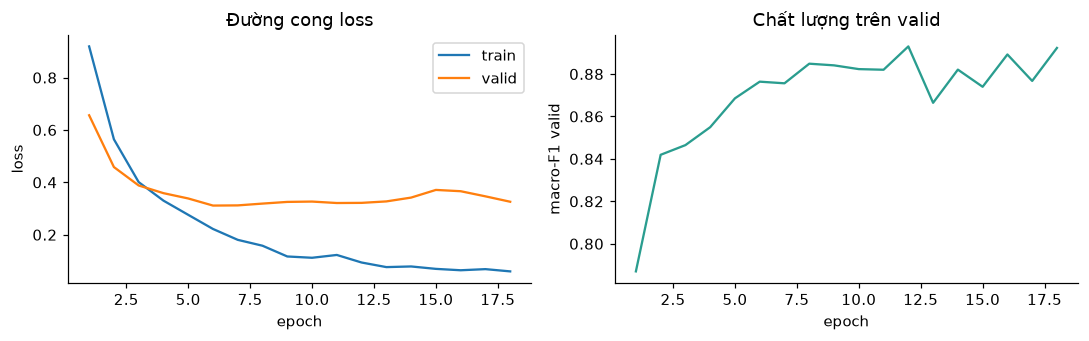

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].plot(hist["epoch"], hist["loss_train"], label="train"); ax[0].plot(hist["epoch"], hist["loss_valid"], label="valid")
ax[0].set_xlabel("epoch"); ax[0].set_ylabel("loss"); ax[0].legend(); ax[0].set_title("Đường cong loss")
ax[1].plot(hist["epoch"], hist["f1_valid"], color="#2a9d8f"); ax[1].set_xlabel("epoch"); ax[1].set_ylabel("macro-F1 valid")
ax[1].set_title("Chất lượng trên valid")
plt.tight_layout(); plt.show()

**Cách đọc đường cong loss.** Loss train luôn giảm; loss valid giảm rồi *ngừng giảm hoặc tăng lên* khi mô hình bắt đầu **quá khớp** (nhớ dữ liệu train). Điểm valid tốt nhất là chỗ nên dừng — đó là điều dừng sớm tự làm.

## 6. So sánh trung thực qua nhiều seed

Một lần huấn luyện mạng nơ-ron phụ thuộc seed (khởi tạo, thứ tự batch, dropout). Báo cáo một con số từ một seed là *chọn quả anh đào*. Ta chạy 5 seed rồi báo cáo trung bình ± độ lệch chuẩn, trên cả `valid` và tập câu khó.

In [10]:
def macro_f1(model, ds):
    return danh_gia(model, ds)[1]

ket_qua = {"TrungBinhEmb": [], "CNN1D": []}
for seed in range(5):
    for ten, ctor in [("TrungBinhEmb", lambda: TrungBinhEmb(V)), ("CNN1D", lambda: CNN1D(V))]:
        set_seed(seed)
        m = ctor()
        huan_luyen(m, seed=seed)
        ket_qua[ten].append((macro_f1(m, ds_va), macro_f1(m, ds_hard)))

# baseline TF-IDF + LR (Bài 3) trên đúng các đặc trưng này
tf = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True, token_pattern=r"(?u)\b\w+\b")
Xtr_ = tf.fit_transform(train["text"].map(normalize))
lr = LogisticRegression(C=10, max_iter=3000).fit(Xtr_, train["label"])
lr_valid = f1_score(valid["label"], lr.predict(tf.transform(valid["text"].map(normalize))), average="macro")
lr_hard = f1_score(hard["label"], lr.predict(tf.transform(hard["text"].map(normalize))), average="macro")

rows = []
for ten, v in ket_qua.items():
    a = np.array(v)
    rows.append({"mô hình": ten, "valid macro-F1": f"{a[:, 0].mean():.3f} ± {a[:, 0].std():.3f}",
                 "câu khó macro-F1": f"{a[:, 1].mean():.3f} ± {a[:, 1].std():.3f}"})
rows.append({"mô hình": "TF-IDF + Logistic Regression", "valid macro-F1": f"{lr_valid:.3f} (tất định)", "câu khó macro-F1": f"{lr_hard:.3f} (tất định)"})
pd.DataFrame(rows)

,mô hình,valid macro-F1,câu khó macro-F1
0,TrungBinhEmb,0.884 ± 0.007,0.496 ± 0.034
1,CNN1D,0.907 ± 0.009,0.514 ± 0.046
2,TF-IDF + Logistic Regression,0.886 (tất định),0.563 (tất định)


Hãy đọc bảng này kỹ trước khi kết luận:

- Mô hình **trung bình embedding** gần như ngang TF-IDF + LR trên valid (≈0,88 so với ≈0,89), đúng như dự đoán vì cùng mất thứ tự.
- **CNN nhỉnh hơn trên valid** (≈0,91): chênh lệch lớn hơn độ lệch chuẩn qua seed (≈0,01), nên đây là chênh lệch thật nhưng nhỏ — nhờ nhìn cụm 2–3 từ.
- **Nhưng trên câu khó, TF-IDF + LR lại tốt hơn cả hai mạng** (≈0,56 so với ≈0,50). Lợi thế của CNN trên valid không bền khi đổi phân phối. Cần nhớ cỡ mẫu: 40 câu khó thì chênh lệch này chỉ là gợi ý.
- Mọi mô hình đều giảm mạnh trên câu khó: huấn luyện trên kho tổng hợp không đủ để dạy mỉa mai hay phủ định phức tạp. Lợi thế thật sự của học sâu đến khi có dữ liệu lớn hoặc dùng **mô hình tiền huấn luyện** (Bài 9–10).

## 7. Kỹ thuật chống quá khớp

| Kỹ thuật | Cách làm | Khi nào |
|---|---|---|
| **Dropout** | tắt ngẫu nhiên một phần nơ-ron khi huấn luyện | gần như luôn dùng ở lớp cuối |
| **Weight decay (L2)** | phạt trọng số lớn (`AdamW(weight_decay=...)`) | mặc định nên có, nhỏ |
| **Dừng sớm** | dừng khi valid hết cải thiện | luôn nên có |
| **Giảm kích thước mô hình** | ít chiều embedding, ít bộ lọc | dữ liệu nhỏ |
| **Tăng cường dữ liệu** | thêm biến thể (không dấu, đổi từ đồng nghĩa) | khi có hiểu biết miền |
| **Thêm dữ liệu** | luôn tốt nhất | |

Thử nghiệm nhanh tác dụng của dropout và kích thước embedding (xem nhận xét bên dưới bảng):

In [11]:
rows = []
for p in [0.0, 0.4]:
    for d_emb in [16, 64, 128]:
        vs = []
        for seed in range(3):
            set_seed(seed)
            m = CNN1D(V, d=d_emb, p=p)
            huan_luyen(m, seed=seed)
            vs.append(macro_f1(m, ds_va))
        rows.append({"dropout": p, "chiều embedding": d_emb, "macro-F1 valid (TB 3 seed)": round(float(np.mean(vs)), 3), "độ lệch chuẩn": round(float(np.std(vs)), 3)})
pd.DataFrame(rows)

,dropout,chiều embedding,macro-F1 valid (TB 3 seed),độ lệch chuẩn
0,0.0,16,0.885,0.012
1,0.0,64,0.902,0.006
2,0.0,128,0.900,0.005
3,0.4,16,0.886,0.003
4,0.4,64,0.905,0.010
5,0.4,128,0.919,0.002


Chiều embedding quá nhỏ (16) thiếu sức biểu diễn (≈0,886); chiều lớn hơn tốt hơn. Dropout 0,4 giúp rõ nhất ở chiều lớn (128: ≈0,92 so với ≈0,90 khi không dropout). Các chênh lệch cỡ 0,01–0,02 chỉ gấp vài lần độ lệch chuẩn, nên hãy coi đó là **gợi ý để thử trên dữ liệu của bạn**, không phải quy luật.

## 8. Tái lập kết quả

Để kết quả chạy lại giống nhau cần: cố định **seed** (`set_seed`), ghi **phiên bản thư viện**, ghi **cấu hình** (siêu tham số), và biết rằng một số phép toán trên GPU không tất định bit-by-bit. Thói quen tốt: ghi các tham số + điểm số vào một bảng/tệp sau mỗi lần chạy.

In [12]:
import json, platform

cau_hinh = {"mô hình": "CNN1D", "d_emb": 64, "kernels": [2, 3], "filters": 64, "dropout": 0.4,
            "lr": 3e-3, "weight_decay": 1e-4, "batch": 64, "seed": 0,
            "torch": torch.__version__, "python": platform.python_version(), "device": device}
print(json.dumps(cau_hinh, ensure_ascii=False, indent=2))

{
  "mô hình": "CNN1D",
  "d_emb": 64,
  "kernels": [
    2,
    3
  ],
  "filters": 64,
  "dropout": 0.4,
  "lr": 0.003,
  "weight_decay": 0.0001,
  "batch": 64,
  "seed": 0,
  "torch": "2.14.0+cu126",
  "python": "3.11.9",
  "device": "cpu"
}


## 9. Tổng kết

- Hồi quy softmax = mạng một lớp; gradient của cross-entropy + softmax là `P − Y`.
- Pipeline PyTorch: từ điển → mã hóa → đệm + mặt nạ → `DataLoader` → vòng huấn luyện + dừng sớm.
- Trung bình embedding ≈ BoW; CNN bắt được cụm từ cục bộ.
- Với dữ liệu nhỏ, TF-IDF + LR là đối thủ rất mạnh: đừng thần thánh hóa học sâu.
- Luôn báo cáo qua nhiều seed.

## Bài tập

1. **(Dễ)** Thay `AdamW` bằng `SGD(momentum=0.9)`. Cần chỉnh `lr` thế nào để hội tụ? So sánh đường cong loss.
2. **(Dễ)** Thêm `kernels=(1, 2, 3, 4)` cho CNN. Điểm thay đổi ra sao?
3. **(Vừa)** Khởi tạo embedding bằng vector Skip-gram từ Bài 5 (`model.emb.weight.data[i] = ...`). Có lợi không với dữ liệu nhỏ?
4. **(Vừa)** Thêm **label smoothing** (`F.cross_entropy(..., label_smoothing=0.1)`). Nó ảnh hưởng thế nào đến loss valid và độ tin cậy dự đoán?
5. **(Khó)** Cài `BiGRU` trung bình theo thời gian (dùng `nn.GRU(bidirectional=True)` + mặt nạ). So với CNN trên câu khó.

<details>
<summary><b>Gợi ý đáp án</b></summary>

1. SGD cần `lr` lớn hơn (≈0,05–0,2) và nhiều epoch hơn; Adam thích ứng tốc độ học từng tham số nên dễ dùng hơn.
2. Thêm kernel 1 ≈ thêm unigram; kernel 4 bắt cụm dài hơn nhưng dễ quá khớp trên dữ liệu nhỏ.
3. Gán trọng số đã huấn luyện cho các từ có trong từ điển chung; thường giúp nhẹ khi dữ liệu có nhãn rất ít, nhưng kho Skip-gram của ta nhỏ nên lợi ích hạn chế.
4. Label smoothing làm loss valid cao hơn một chút (không còn muốn xác suất = 1) nhưng thường cải thiện hiệu chuẩn.
5. `out, _ = gru(emb)` rồi lấy trung bình theo mặt nạ trên chiều thời gian; cần `pack_padded_sequence` nếu muốn bỏ ô đệm triệt để.
</details>

**Tiếp theo → Bài 7:** mô hình chuỗi (RNN, LSTM, GRU) và gán nhãn chuỗi.

**Đọc thêm:** Kim, *Convolutional Neural Networks for Sentence Classification* (2014) · Joulin và cộng sự, *Bag of Tricks for Efficient Text Classification* (fastText, 2016) · [PyTorch tutorials](https://pytorch.org/tutorials/)